# **Classificação de texto com spaCy**

## Etapa 1: Importação e instalação das bibliotecas

In [1]:
import os
import random
import string
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import spacy
from spacy.lang.pt.stop_words import STOP_WORDS

## Etapa 2: Carregamento da base de dados

In [2]:
DRIVE_DIRECTORY = Path.cwd().parent / "data"

In [3]:
base_dados = pd.read_csv(
    os.path.join(DRIVE_DIRECTORY, "base_treinamento.txt"), encoding="utf-8"
)
base_dados

,texto,emocao
0,este trabalho é agradável,alegria
1,gosto de ficar no seu aconchego,alegria
2,fiz a adesão ao curso hoje,alegria
3,eu sou admirada por muitos,alegria
4,adoro como você,alegria
...,...,...
191,estou chocado e amedrontado com este assassina...,medo
192,é preciso afugenta com ímpeto este medo do inf...,medo
193,políticos usam suas forças para afugentar e am...,medo
194,o objetivo disso e apenas me amedrontar mais,medo


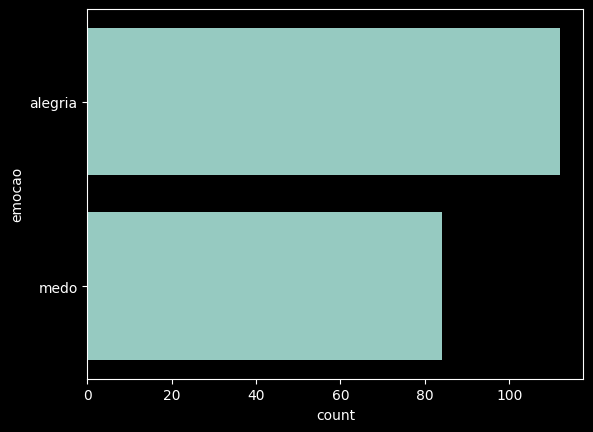

In [4]:
sns.countplot(base_dados["emocao"], label="Contagem");

## Etapa 3: Função para pré-processamento dos textos

In [5]:
pontuacoes = string.punctuation
pontuacoes

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [6]:
stop_words = STOP_WORDS
len(stop_words)

416

In [7]:
pln = spacy.load("pt_core_news_sm")
pln

In [8]:
def preprocessamento(texto):
    texto = texto.lower()
    documento = pln(texto)
    lista = []

    for token in documento:
        lista.append(token.lemma_)

    lista = [
        palavra
        for palavra in lista
        if palavra not in stop_words and palavra not in pontuacoes
    ]
    lista = " ".join([
        str(elemento) for elemento in lista if not elemento.isdigit()
    ])

    return lista

In [9]:
teste = "Estou aprendendo processamento 112233 de linguagem natural, curso em Curitiba"
preprocessamento(teste)

'aprender processamento linguagem natural curso curitber'

## Etapa 4: Pré-processamento da base de dados

### Limpeza dos textos

In [10]:
base_dados.head(10)

,texto,emocao
0,este trabalho é agradável,alegria
1,gosto de ficar no seu aconchego,alegria
2,fiz a adesão ao curso hoje,alegria
3,eu sou admirada por muitos,alegria
4,adoro como você,alegria
5,adoro seu cabelo macio,alegria
6,adoro a cor dos seus olhos,alegria
7,somo tão amáveis um com o outro,alegria
8,sinto uma grande afeição por ele,alegria
9,quero agradar meus filhos,alegria


In [11]:
base_dados['texto'] = base_dados['texto'].apply(preprocessamento)
base_dados

,texto,emocao
0,trabalho agradável,alegria
1,gostar ficar em o aconchego,alegria
2,fiz adesão a o curso hoje,alegria
3,admirar,alegria
4,adorar,alegria
...,...,...
191,chocado amedrontar assassinato brutal,medo
192,preciso afugentar ímpeto medo de o inferno,medo
193,político força afugentar amedrontar,medo
194,objetivo de isso amedrontar,medo


### Tratamento da classe

In [12]:
base_dados_final = []
for texto, emocao in zip(base_dados['texto'], base_dados['emocao']):
    if emocao == 'alegria':
        dic = ({'ALEGRIA': True, 'MEDO': False})
    elif emocao == 'medo':
        dic = ({'ALEGRIA': False, 'MEDO': True})
    base_dados_final.append([texto, dic.copy()])

base_dados_final

[['trabalho agradável', {'ALEGRIA': True, 'MEDO': False}],
 ['gostar ficar em o aconchego', {'ALEGRIA': True, 'MEDO': False}],
 ['fiz adesão a o curso hoje', {'ALEGRIA': True, 'MEDO': False}],
 ['admirar', {'ALEGRIA': True, 'MEDO': False}],
 ['adorar', {'ALEGRIA': True, 'MEDO': False}],
 ['adorar cabelo macio', {'ALEGRIA': True, 'MEDO': False}],
 ['adorar cor de o olho', {'ALEGRIA': True, 'MEDO': False}],
 ['somo amável outro', {'ALEGRIA': True, 'MEDO': False}],
 ['sinto afeição', {'ALEGRIA': True, 'MEDO': False}],
 ['querer agradar filho', {'ALEGRIA': True, 'MEDO': False}],
 ['sinto completamente amar', {'ALEGRIA': True, 'MEDO': False}],
 ['amar', {'ALEGRIA': True, 'MEDO': False}],
 ['alívio', {'ALEGRIA': True, 'MEDO': False}],
 ['dor amenizar finalmente', {'ALEGRIA': True, 'MEDO': False}],
 ['achar apaixonar', {'ALEGRIA': True, 'MEDO': False}],
 ['amar maravilhoso', {'ALEGRIA': True, 'MEDO': False}],
 ['sentir animar', {'ALEGRIA': True, 'MEDO': False}],
 ['sinto hoje', {'ALEGRIA': Tr

## Etapa 5: Criação do classificador

## Etapa 6: Testes com uma frase

## Etapa 7: Avaliação do modelo